<a href="https://colab.research.google.com/github/rolandogonzales-deeptech/Research-Methods-UNMSM-2026-II/blob/main/Session6_Your_Turn_Completed_(1)_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 6 · Hands-On Labs / Laboratorios prácticos
## Experimental Best Practices: Splits, Seeds & Statistical Rigor
## Buenas prácticas experimentales: particiones, semillas y rigor estadístico
**Doctoral Program in Deep Technologies · UNMSM · Dr. Loveleen Gaur**

Six short labs. Each one takes a claim from the slides and lets you **see it happen with your own eyes**.
No installation: open in Google Colab and press `Shift + Enter` on each cell.

> **ES:** Seis laboratorios cortos. Cada uno toma una afirmación de las diapositivas y te permite **verla ocurrir con tus propios ojos**. Sin instalación: ábrelo en Google Colab y presiona `Shift + Enter` en cada celda.

| Lab | English | Español | The trap it exposes / La trampa |
|---|---|---|---|
| 1 | The Seed Lottery | La lotería de la semilla | One run is luck / Una sola corrida es suerte |
| 2 | The Leak Detector | El detector de fugas | Test data sneaks into training / El test se filtra al entrenamiento |
| 3 | The Patient Twins | Los pacientes gemelos | Same person in train and test / La misma persona en train y test |
| 4 | The Peeking Simulator | El simulador de "espiar" | Stopping when you like the result / Parar cuando te gusta el resultado |
| 5 | Significant ≠ Important | Significativo ≠ importante | p-values without effect sizes / Valores p sin tamaño del efecto |
| 6 | The Fair Fight | La pelea justa | Comparing models the wrong way / Comparar modelos mal |

**How to use each lab / Cómo usar cada lab:**
1. 🤔 **Predict** first (write your guess in the cell). / **Predice** primero.
2. ▶️ **Run** the code. / **Ejecuta** el código.
3. 💡 **Explain** what surprised you to your neighbor. / **Explica** a tu compañero qué te sorprendió.

In [1]:
# Run me first / Ejecútame primero
import warnings; warnings.filterwarnings("ignore")   # hide convergence chatter / ocultar avisos
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, cross_val_score, StratifiedKFold,
                                     GroupKFold, KFold, RepeatedStratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

NAVY, TEAL, AMBER, RED = "#0F2233", "#14897F", "#F2A33A", "#D9534F"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
print("Ready / Listo ✅")

Ready / Listo ✅


---
## Lab 1 · The Seed Lottery 🎲 / La lotería de la semilla
**Slide claim:** a single run is a coin toss.
**ES · Afirmación:** una sola corrida es un volado (cara o sello).

**The story.** Two PhD students train *the same* small neural network on *the same* breast-cancer dataset. The only difference is the **random seed**, the starting number for the computer's "dice". One writes "our model reaches 98%". The other writes "only 95%". Who is right? **Both, and neither.**

> **ES · La historia.** Dos doctorandos entrenan *la misma* red neuronal pequeña con *el mismo* conjunto de datos de cáncer de mama. La única diferencia es la **semilla aleatoria**, el número inicial de los "dados" de la computadora. Uno escribe "nuestro modelo llega a 98%". El otro, "solo 95%". ¿Quién tiene razón? **Ambos, y ninguno.**

🤔 **Predict / Predice:** across 20 seeds, how many percentage points between the best and worst run? / En 20 semillas, ¿cuántos puntos entre la mejor y la peor corrida?

`My guess / Mi apuesta: ____ points`

In [2]:
X, y = load_breast_cancer(return_X_y=True)     # 569 real patients / 569 pacientes reales

accuracies = []
for seed in range(20):                          # 20 rolls of the dice / 20 tiradas de dados
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
    scaler = StandardScaler().fit(Xtr)          # learn scaling from TRAIN only / escalar solo con TRAIN
    Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
    model = MLPClassifier(hidden_layer_sizes=(16,), max_iter=300, random_state=seed)
    model.fit(Xtr_s, ytr)
    accuracies.append(model.score(Xte_s, yte) * 100)

accuracies = np.array(accuracies)
print(f"Best run  / Mejor corrida : {accuracies.max():.1f}%   (seed {accuracies.argmax()})")
print(f"Worst run / Peor corrida  : {accuracies.min():.1f}%   (seed {accuracies.argmin()})")
print(f"Spread    / Rango         : {accuracies.max()-accuracies.min():.1f} percentage points")
print(f"Honest report / Reporte honesto -> {accuracies.mean():.1f}% ± {accuracies.std(ddof=1):.1f}% (mean ± SD, n=20)")

Best run  / Mejor corrida : 98.2%   (seed 6)
Worst run / Peor corrida  : 94.7%   (seed 8)
Spread    / Rango         : 3.5 percentage points
Honest report / Reporte honesto -> 97.2% ± 1.0% (mean ± SD, n=20)


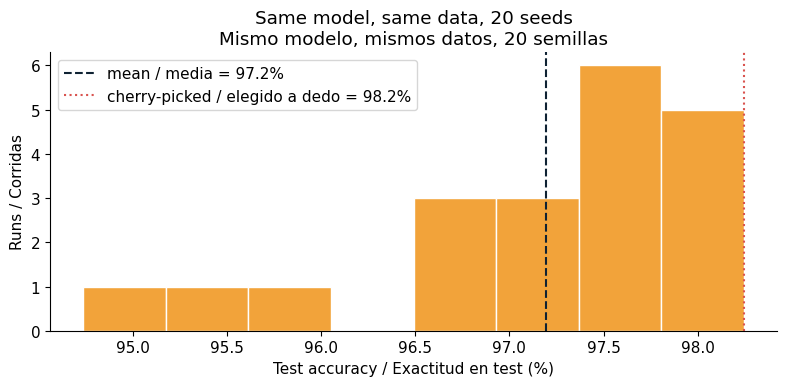

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(accuracies, bins=8, color=AMBER, edgecolor="white")
plt.axvline(accuracies.mean(), color=NAVY, linestyle="--", label=f"mean / media = {accuracies.mean():.1f}%")
plt.axvline(accuracies.max(), color=RED, linestyle=":", label=f"cherry-picked / elegido a dedo = {accuracies.max():.1f}%")
plt.title("Same model, same data, 20 seeds\nMismo modelo, mismos datos, 20 semillas")
plt.xlabel("Test accuracy / Exactitud en test (%)"); plt.ylabel("Runs / Corridas")
plt.legend(); plt.tight_layout(); plt.show()

### 1b · Where does the luck come from? / ¿De dónde viene la suerte?
There are **two dice**: (1) which patients land in the test set (the *split*), and (2) where the network starts learning (the *initialization*). Let's roll each one separately.

> **ES:** Hay **dos dados**: (1) qué pacientes caen en el conjunto de test (la *partición*) y (2) desde dónde empieza a aprender la red (la *inicialización*). Tiremos cada uno por separado.

In [4]:
def run(split_seed, init_seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=split_seed, stratify=y)
    sc = StandardScaler().fit(Xtr)
    m = MLPClassifier(hidden_layer_sizes=(16,), max_iter=300, random_state=init_seed)
    return m.fit(sc.transform(Xtr), ytr).score(sc.transform(Xte), yte) * 100

only_split = np.array([run(s, 0) for s in range(20)])   # change split only / solo cambia la partición
only_init  = np.array([run(0, s) for s in range(20)])   # change init only  / solo cambia la inicialización
print(f"Only the SPLIT changes / Solo cambia la PARTICIÓN      : SD = {only_split.std(ddof=1):.2f} pts, range = {np.ptp(only_split):.1f}")
print(f"Only the INIT changes  / Solo cambia la INICIALIZACIÓN : SD = {only_init.std(ddof=1):.2f} pts, range = {np.ptp(only_init):.1f}")

Only the SPLIT changes / Solo cambia la PARTICIÓN      : SD = 1.01 pts, range = 4.1
Only the INIT changes  / Solo cambia la INICIALIZACIÓN : SD = 0.77 pts, range = 2.9


💡 **What you should see / Qué deberías ver:** accuracy is a **band, not a number**. On small datasets (like most management and health datasets), *which cases land in the test set* usually matters more than the network's starting point.

**The honest move:** report **mean ± standard deviation over many seeds**, and say which randomness you varied.

> **ES:** la exactitud es una **franja, no un número**. En datos pequeños (como la mayoría de datos de gestión y salud), *qué casos caen en el test* suele importar más que el punto de partida de la red. **Lo honesto:** reportar **media ± desviación estándar sobre muchas semillas** e indicar qué aleatoriedad variaste.

---
## Lab 2 · The Leak Detector 💧 / El detector de fugas
**Slide claim:** if information from the test set touches training, your score is fiction.
**ES · Afirmación:** si información del test toca el entrenamiento, tu resultado es ficción.

### 2a · The small leak: scaling before splitting / La fuga pequeña: escalar antes de partir

In [5]:
def evaluate(leaky, seed=0):
    if leaky:
        # WRONG / INCORRECTO: scale the WHOLE dataset first, the scaler "sees" the test set
        Xs = StandardScaler().fit_transform(X)
        Xtr, Xte, ytr, yte = train_test_split(Xs, y, test_size=0.3, random_state=seed, stratify=y)
    else:
        # RIGHT / CORRECTO: split first, then learn scaling from TRAIN only
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
        sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    return LogisticRegression(max_iter=2000).fit(Xtr, ytr).score(Xte, yte) * 100

leaky_a = np.mean([evaluate(True, s) for s in range(30)])
clean_a = np.mean([evaluate(False, s) for s in range(30)])
print(f"Leaky / Con fuga : {leaky_a:.2f}%")
print(f"Clean / Limpio   : {clean_a:.2f}%")
print(f"Difference / Diferencia: {leaky_a-clean_a:+.2f} points")

Leaky / Con fuga : 97.60%
Clean / Limpio   : 97.56%
Difference / Diferencia: +0.04 points


**Honest note / Nota honesta:** with simple scaling on a clean dataset, the gap is **tiny**. That is exactly why this leak survives peer review: it *looks* harmless. Now watch a leak that is **not** harmless.

> **ES:** con un escalado simple en datos limpios, la diferencia es **mínima**. Por eso esta fuga sobrevive a la revisión por pares: *parece* inofensiva. Ahora mira una fuga que **no** es inofensiva.

### 2b · The big leak: "Predicting the unpredictable" / La fuga grande: "Predecir lo impredecible"
We create **pure noise**: 100 "customers", 5,000 random features, and a **coin-flip** label. There is *nothing* to learn. An honest model must score about **50%**.

The leaky researcher first picks the 20 features "most related to the label" using **all** the data, then runs cross-validation.

> **ES:** Creamos **ruido puro**: 100 "clientes", 5 000 variables aleatorias y una etiqueta tirada **a cara o sello**. No hay *nada* que aprender. Un modelo honesto debe dar cerca de **50%**. El investigador con fuga primero elige las 20 variables "más relacionadas con la etiqueta" usando **todos** los datos y luego hace validación cruzada.

🤔 **Predict / Predice:** what accuracy will the leaky researcher report on pure noise? / ¿Qué exactitud reportará sobre ruido puro?

Leaky researcher on PURE NOISE / Investigador con fuga sobre RUIDO PURO: 90%  🚨
Clean pipeline   on PURE NOISE / Pipeline limpio sobre RUIDO PURO      : 45%  ✅ (chance / azar = 50%)


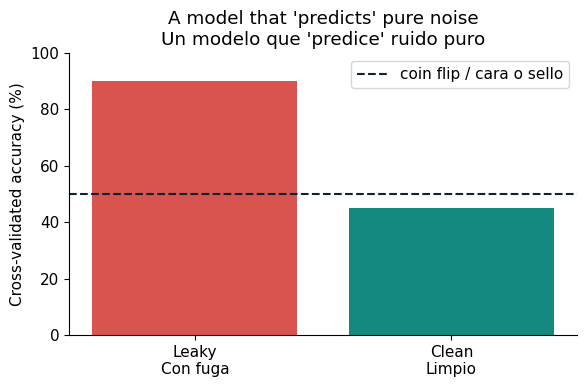

In [6]:
rng = np.random.default_rng(42)
X_noise = rng.normal(size=(100, 5000))          # random features / variables al azar
y_noise = rng.integers(0, 2, size=100)          # coin-flip label / etiqueta a cara o sello
cv = StratifiedKFold(5, shuffle=True, random_state=0)

# LEAKY / CON FUGA: feature selection on ALL rows, then cross-validate
X_sel = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
leaky_b = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_noise, cv=cv).mean() * 100

# CLEAN / LIMPIO: selection happens INSIDE each fold via a Pipeline
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
clean_b = cross_val_score(pipe, X_noise, y_noise, cv=cv).mean() * 100

print(f"Leaky researcher on PURE NOISE / Investigador con fuga sobre RUIDO PURO: {leaky_b:.0f}%  🚨")
print(f"Clean pipeline   on PURE NOISE / Pipeline limpio sobre RUIDO PURO      : {clean_b:.0f}%  ✅ (chance / azar = 50%)")

plt.figure(figsize=(6, 4))
plt.bar(["Leaky\nCon fuga", "Clean\nLimpio"], [leaky_b, clean_b], color=[RED, TEAL])
plt.axhline(50, color=NAVY, ls="--", label="coin flip / cara o sello")
plt.ylim(0, 100); plt.ylabel("Cross-validated accuracy (%)")
plt.title("A model that 'predicts' pure noise\nUn modelo que 'predice' ruido puro"); plt.legend(); plt.tight_layout(); plt.show()

💡 **What you should see:** the leaky setup reports a high, publishable-looking accuracy **on data with no signal at all**. The fix is one line: put every data-dependent step (scaling, imputing, selecting, oversampling with SMOTE) **inside a `Pipeline`**, so it is re-learned inside each training fold.

This is the mistake behind many of the **294 leaky papers in 17 fields** found by Kapoor & Narayanan (2023, *Patterns*).

> **ES:** la versión con fuga reporta una exactitud alta y "publicable" **sobre datos sin ninguna señal**. La solución es una línea: poner todo paso que depende de los datos (escalar, imputar, seleccionar, sobremuestrear con SMOTE) **dentro de un `Pipeline`**, para que se reaprenda en cada pliegue de entrenamiento. Es el error detrás de muchos de los **294 artículos con fuga en 17 campos** (Kapoor y Narayanan, 2023).

---
## Lab 3 · The Patient Twins 👯 / Los pacientes gemelos
**Slide claim:** if the same person appears in training *and* test, the model memorizes **people**, not **disease**.
**ES · Afirmación:** si la misma persona aparece en entrenamiento *y* test, el modelo memoriza **personas**, no **enfermedades**.

**The story.** A hospital gives you 10 scans per patient for 80 patients. Each patient's scans share a personal "fingerprint" (body shape, scanner, positioning). The real disease signal is **weak**. You split the *scans* at random...

> **ES · La historia.** Un hospital te da 10 imágenes por paciente de 80 pacientes. Las imágenes de cada paciente comparten una "huella" personal (contextura, escáner, posición). La señal real de la enfermedad es **débil**. Tú partes las *imágenes* al azar...

The same trap appears in business: several transactions per customer, several visits per store, several quarters per firm.
> **ES:** La misma trampa aparece en negocios: varias transacciones por cliente, varias visitas por tienda, varios trimestres por empresa.

In [7]:
rng = np.random.default_rng(7)
n_patients, scans_each, n_feat = 80, 10, 30
diagnosis   = rng.integers(0, 2, n_patients)                     # 1 = sick / enfermo
fingerprint = rng.normal(0, 3.0, size=(n_patients, n_feat))      # strong personal signature / huella fuerte
disease_dir = rng.normal(0, 1, n_feat); disease_dir /= np.linalg.norm(disease_dir)

Xp, yp, groups = [], [], []
for p in range(n_patients):
    for _ in range(scans_each):
        scan = fingerprint[p] + 0.6 * diagnosis[p] * disease_dir + rng.normal(0, 1, n_feat)  # weak disease signal
        Xp.append(scan); yp.append(diagnosis[p]); groups.append(p)
Xp, yp, groups = np.array(Xp), np.array(yp), np.array(groups)

rf = RandomForestClassifier(n_estimators=200, random_state=0)
by_scan    = cross_val_score(rf, Xp, yp, cv=KFold(5, shuffle=True, random_state=0)).mean() * 100
by_patient = cross_val_score(rf, Xp, yp, cv=GroupKFold(5), groups=groups).mean() * 100

print(f"Split by SCAN    (patients in both sides) / Partición por IMAGEN  : {by_scan:.0f}%  🚨")
print(f"Split by PATIENT (each patient one side)  / Partición por PACIENTE: {by_patient:.0f}%  ✅")

Split by SCAN    (patients in both sides) / Partición por IMAGEN  : 99%  🚨
Split by PATIENT (each patient one side)  / Partición por PACIENTE: 54%  ✅


💡 **What you should see:** splitting by scan looks brilliant; splitting by patient reveals the truth. The fix is `GroupKFold` (or `StratifiedGroupKFold`) with the person, customer, store or firm as the **group**.

> **ES:** partir por imagen se ve brillante; partir por paciente revela la verdad. La solución es `GroupKFold` (o `StratifiedGroupKFold`) usando a la persona, cliente, tienda o empresa como **grupo**.

**Real case / Caso real:** Zech et al. (2018, *PLOS Medicine*) showed a pneumonia X-ray network could identify *which hospital* an image came from, and its performance dropped on hospitals it had not seen. Roberts et al. (2021, *Nature Machine Intelligence*) reviewed 2,212 COVID-19 imaging ML studies; of the 62 that reached full review, **none** was ready for clinical use, with data duplication and leakage among the pitfalls.

---
## Lab 4 · The Peeking Simulator 👀 / El simulador de "espiar"
**Slide claim:** checking results again and again, and stopping when you like them, turns a 5% false-alarm rate into 20%+.
**ES · Afirmación:** revisar los resultados una y otra vez y parar cuando te gustan convierte un 5% de falsas alarmas en más de 20%.

We simulate an **A/A test**: two web pages that are **identical**. Any "winner" is a false alarm. A correct test should cry wolf only about **5%** of the time.

> **ES:** Simulamos una **prueba A/A**: dos páginas web **idénticas**. Cualquier "ganador" es una falsa alarma. Una prueba correcta solo debería gritar "¡lobo!" cerca del **5%** de las veces.

🤔 **Predict / Predice:** if you peek 10 times, what false-alarm rate? / Si espías 10 veces, ¿qué tasa de falsas alarmas?

False winners, no peeking  / Falsos ganadores sin espiar  : 4.7%  (target / meta ≈ 5%)
False winners, peeking 10x / Falsos ganadores espiando 10x: 18.6%


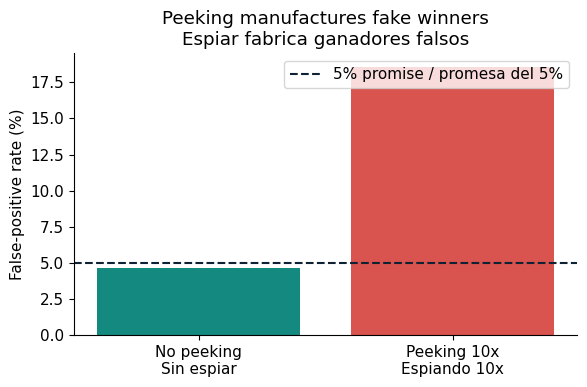

In [8]:
def run_experiment(peek, n_final=2000, checks=10, seed=0):
    rng = np.random.default_rng(seed)
    a = rng.random(n_final) < 0.10        # both pages convert at 10% / ambas convierten al 10%
    b = rng.random(n_final) < 0.10
    if not peek:                          # honest: look ONCE at the planned size / mirar UNA vez
        return stats.ttest_ind(a, b).pvalue < 0.05
    for k in range(1, checks + 1):        # peeking: stop at the first p < 0.05 / parar al primer p < 0.05
        m = int(n_final * k / checks)
        if stats.ttest_ind(a[:m], b[:m]).pvalue < 0.05:
            return True
    return False

N = 2000
honest_fp = np.mean([run_experiment(False, seed=s) for s in range(N)]) * 100
peek_fp   = np.mean([run_experiment(True,  seed=s) for s in range(N)]) * 100
print(f"False winners, no peeking  / Falsos ganadores sin espiar  : {honest_fp:.1f}%  (target / meta ≈ 5%)")
print(f"False winners, peeking 10x / Falsos ganadores espiando 10x: {peek_fp:.1f}%")

plt.figure(figsize=(6, 4))
plt.bar(["No peeking\nSin espiar", "Peeking 10x\nEspiando 10x"], [honest_fp, peek_fp], color=[TEAL, RED])
plt.axhline(5, color=NAVY, ls="--", label="5% promise / promesa del 5%")
plt.ylabel("False-positive rate (%)"); plt.title("Peeking manufactures fake winners\nEspiar fabrica ganadores falsos")
plt.legend(); plt.tight_layout(); plt.show()

### 4b · The garden of forking paths / El jardín de los senderos que se bifurcan
Peeking over *time* is one trap. Peeking over *subgroups* is another: "no effect overall... but let's check women, men, Lima, provinces, under 30, over 60...". Run 20 subgroup tests on data where **nothing is real**.

> **ES:** Espiar en el *tiempo* es una trampa. Espiar en *subgrupos* es otra: "no hay efecto global... pero revisemos mujeres, hombres, Lima, provincias, menores de 30, mayores de 60...". Hagamos 20 pruebas por subgrupo en datos donde **nada es real**.

In [9]:
rng = np.random.default_rng(3)
studies, subgroups = 2000, 20
found_any, found_any_holm = 0, 0
for _ in range(studies):
    p = np.array([stats.ttest_ind(rng.normal(size=50), rng.normal(size=50)).pvalue for _ in range(subgroups)])
    found_any += (p < 0.05).any()
    # Holm correction / corrección de Holm
    order = np.sort(p); thresholds = 0.05 / (subgroups - np.arange(subgroups))
    found_any_holm += (order[0] < thresholds[0])
print(f"Studies with at least one 'discovery' / Estudios con al menos un 'hallazgo': {found_any/studies*100:.0f}%  🚨")
print(f"...after Holm correction / ...tras la corrección de Holm                   : {found_any_holm/studies*100:.1f}%  ✅")

Studies with at least one 'discovery' / Estudios con al menos un 'hallazgo': 66%  🚨
...after Holm correction / ...tras la corrección de Holm                   : 4.7%  ✅


💡 **What you should see:** with 20 looks, most null studies "find" something. Holm (or Bonferroni) brings it back to about 5%.

**The fix:** decide the sample size, the metric and the subgroups **before** you start (pre-registration), analyze once, and correct for multiple comparisons. If you must monitor, use sequential methods built for it.

**Real numbers:** Kohavi, Deng & Vermeer (KDD 2022) estimate that when only about 8 to 10% of ideas truly work (Airbnb Search, Booking.com, Netflix), **22 to 26% of "significant" A/B wins are false positives**, even with no peeking at all.

> **ES:** con 20 miradas, la mayoría de estudios nulos "encuentra" algo. Holm (o Bonferroni) lo regresa a cerca de 5%. **La solución:** decidir el tamaño de muestra, la métrica y los subgrupos **antes** de empezar (pre-registro), analizar una vez y corregir por comparaciones múltiples. **Cifras reales:** Kohavi, Deng y Vermeer (KDD 2022) estiman que cuando solo 8 a 10% de las ideas funcionan, **22 a 26% de los "éxitos significativos" son falsos positivos**, incluso sin espiar.

---
## Lab 5 · Significant ≠ Important ⚖️ / Significativo ≠ importante
**Slide claim:** a p-value tells you *if* something is probably real, not *how big* it is.
**ES · Afirmación:** el valor p te dice *si* algo probablemente es real, no *qué tan grande* es.

### 5a · The giant sample / La muestra gigante
An online store with **5 million visitors per version** changes a button color. Conversion goes from 10.00% to 10.05%.

> **ES:** Una tienda en línea con **5 millones de visitantes por versión** cambia el color de un botón. La conversión pasa de 10.00% a 10.05%.

In [10]:
rng = np.random.default_rng(11)
n = 5_000_000
conv_a = rng.binomial(n, 0.1000); conv_b = rng.binomial(n, 0.1005)
pa, pb = conv_a / n, conv_b / n
diff = pb - pa
se = np.sqrt(pa*(1-pa)/n + pb*(1-pb)/n)
z = diff / se; p = 2 * (1 - stats.norm.cdf(abs(z)))
lo, hi = diff - 1.96*se, diff + 1.96*se
print(f"A: {pa*100:.3f}%   B: {pb*100:.3f}%")
print(f"p-value / valor p: {p:.1e}   -> 'statistically significant!' / '¡estadísticamente significativo!'")
print(f"Effect / Efecto  : {diff*100:+.3f} percentage points, 95% CI [{lo*100:+.3f}, {hi*100:+.3f}]")
print(f"Relative lift / Mejora relativa: {diff/pa*100:+.2f}%  -> worth the redesign cost? / ¿vale el costo del rediseño?")

A: 9.990%   B: 10.073%
p-value / valor p: 1.5e-05   -> 'statistically significant!' / '¡estadísticamente significativo!'
Effect / Efecto  : +0.082 percentage points, 95% CI [+0.045, +0.120]
Relative lift / Mejora relativa: +0.82%  -> worth the redesign cost? / ¿vale el costo del rediseño?


### 5b · The tiny pilot / El piloto diminuto
Now the opposite: a training program for 20 vs 20 employees that **really** improves performance by a meaningful amount (Cohen's *d* ≈ 0.6).

> **ES:** Ahora lo contrario: un programa de capacitación con 20 vs 20 empleados que **realmente** mejora el desempeño en una magnitud importante (*d* de Cohen ≈ 0.6).

In [11]:
rng = np.random.default_rng(5)
control = rng.normal(70, 10, 20)            # performance score / puntaje de desempeño
trained = rng.normal(76, 10, 20)            # true effect = +6 points (d = 0.6) / efecto real = +6
t = stats.ttest_ind(trained, control)
d = (trained.mean() - control.mean()) / np.sqrt((trained.var(ddof=1) + control.var(ddof=1)) / 2)
diff = trained.mean() - control.mean()
se = np.sqrt(trained.var(ddof=1)/20 + control.var(ddof=1)/20)
ci = stats.t.interval(0.95, df=38, loc=diff, scale=se)
print(f"p-value / valor p : {t.pvalue:.3f}   -> 'not significant' / 'no significativo'")
print(f"Effect / Efecto   : {diff:+.1f} points, Cohen's d = {d:.2f}, 95% CI [{ci[0]:+.1f}, {ci[1]:+.1f}]")
print("The CI includes BIG effects. 'Not significant' here means 'not enough data', NOT 'no effect'.")
print("El IC incluye efectos GRANDES. 'No significativo' aquí significa 'faltan datos', NO 'no hay efecto'.")

# How many people would we need? / ¿Cuántas personas necesitaríamos?
from math import ceil
z_a, z_b = stats.norm.ppf(0.975), stats.norm.ppf(0.80)
n_needed = ceil(2 * ((z_a + z_b) / 0.6) ** 2)
print(f"\nPower analysis / Análisis de potencia: about {n_needed} per group for 80% power at d = 0.6")

p-value / valor p : 0.202   -> 'not significant' / 'no significativo'
Effect / Efecto   : +3.4 points, Cohen's d = 0.41, 95% CI [-1.9, +8.8]
The CI includes BIG effects. 'Not significant' here means 'not enough data', NOT 'no effect'.
El IC incluye efectos GRANDES. 'No significativo' aquí significa 'faltan datos', NO 'no hay efecto'.

Power analysis / Análisis de potencia: about 44 per group for 80% power at d = 0.6


### 5c · Your accuracy also needs an interval / Tu exactitud también necesita un intervalo
A test set of 171 patients is small. How sure are we about "97% accuracy"? The **bootstrap** resamples the test set 2,000 times to find out.

> **ES:** Un conjunto de test de 171 pacientes es pequeño. ¿Qué tan seguros estamos de "97% de exactitud"? El **bootstrap** remuestrea el test 2 000 veces para averiguarlo.

In [12]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xtr, ytr)
correct = (clf.predict(Xte) == yte).astype(float)
rng = np.random.default_rng(0)
boot = [rng.choice(correct, size=len(correct), replace=True).mean() * 100 for _ in range(2000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Accuracy / Exactitud: {correct.mean()*100:.1f}%   95% bootstrap CI [{lo:.1f}%, {hi:.1f}%]   (n_test = {len(yte)})")

Accuracy / Exactitud: 95.9%   95% bootstrap CI [93.0%, 98.8%]   (n_test = 171)


💡 **Takeaway / Conclusión:** always report three things: **effect size**, **confidence interval**, and **p-value** (in that order of importance for decisions). Huge samples make trivial effects "significant"; tiny samples hide real ones.

> **ES:** reporta siempre tres cosas: **tamaño del efecto**, **intervalo de confianza** y **valor p** (en ese orden de importancia para decidir). Las muestras enormes vuelven "significativos" efectos triviales; las muestras pequeñas esconden efectos reales.

---
## Lab 6 · The Fair Fight 🥊 / La pelea justa
**New idea:** to claim "Model B beats Model A", compare them on **the same folds** (paired), repeat, and use a test that knows the folds overlap.
**ES · Idea nueva:** para afirmar "el modelo B le gana al A", compáralos en **los mismos pliegues** (pareados), repite y usa una prueba que sepa que los pliegues se solapan.

The usual t-test assumes every fold is independent. They are not: the training sets share most of their rows. So the naive test is **over-confident**. The Nadeau and Bengio (2003) *corrected resampled t-test* fixes this.

> **ES:** La prueba t usual asume que cada pliegue es independiente. No lo son: los conjuntos de entrenamiento comparten la mayoría de filas. Por eso la prueba ingenua es **demasiado confiada**. La *prueba t remuestreada corregida* de Nadeau y Bengio (2003) lo corrige.

In [13]:
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=0)
model_a = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
model_b = RandomForestClassifier(n_estimators=200, random_state=0)
acc_a = cross_val_score(model_a, X, y, cv=cv) * 100     # same folds for both / mismos pliegues
acc_b = cross_val_score(model_b, X, y, cv=cv) * 100
d = acc_a - acc_b                                       # paired differences / diferencias pareadas
k = len(d); n_test = len(y) // 10; n_train = len(y) - n_test

t_naive = d.mean() / (d.std(ddof=1) / np.sqrt(k))
p_naive = 2 * stats.t.sf(abs(t_naive), df=k-1)
t_corr = d.mean() / np.sqrt((1/k + n_test/n_train) * d.var(ddof=1))
p_corr = 2 * stats.t.sf(abs(t_corr), df=k-1)

print(f"Logistic Regression : {acc_a.mean():.2f}% ± {acc_a.std(ddof=1):.2f}")
print(f"Random Forest       : {acc_b.mean():.2f}% ± {acc_b.std(ddof=1):.2f}")
print(f"Mean paired gap / Diferencia media pareada: {d.mean():+.2f} points")
print(f"Naive t-test     / Prueba t ingenua   : p = {p_naive:.4f}")
print(f"Corrected t-test / Prueba t corregida : p = {p_corr:.4f}")

Logistic Regression : 97.80% ± 1.81
Random Forest       : 96.17% ± 2.58
Mean paired gap / Diferencia media pareada: +1.64 points
Naive t-test     / Prueba t ingenua   : p = 0.0000
Corrected t-test / Prueba t corregida : p = 0.0724


💡 **What you should see:** the naive test is far more confident than the corrected one, so a "significant" win under the naive test can disappear once the overlap is accounted for.

**Which test when? / ¿Qué prueba usar?**
| Situation / Situación | Use / Usa |
|---|---|
| 2 models, 1 dataset, repeated CV | Corrected resampled t-test (Nadeau & Bengio, 2003) or 5x2cv (Dietterich, 1998) |
| 2 models, 1 fixed test set | McNemar's test on the paired predictions |
| 2 models, many datasets | Wilcoxon signed-rank test (Demšar, 2006) |
| 3+ models, many datasets | Friedman test + Nemenyi post-hoc (Demšar, 2006) |

### ✍️ The honest results sentence / La oración honesta de resultados
> *"Across 10×10 repeated stratified CV, logistic regression reached 97.8% ± 1.8 and random forest 96.2% ± 2.6 (mean paired difference +1.6 points; corrected resampled t-test p = 0.07, so the difference is not statistically reliable)."*
>
> *"En validación cruzada estratificada repetida 10×10, la regresión logística alcanzó 97.8% ± 1.8 y el bosque aleatorio 96.2% ± 2.6 (diferencia media pareada +1.6 puntos; prueba t remuestreada corregida p = 0.07, por lo que la diferencia no es estadísticamente confiable)."*

Your numbers may differ slightly by library version; use **your** output. / Tus números pueden variar levemente según la versión; usa **tu** resultado.

---
## 🧰 Reproducibility kit / Kit de reproducibilidad
Copy this cell into every project. It fixes the seeds and prints the "ingredients label" of your experiment.
> **ES:** Copia esta celda en cada proyecto. Fija las semillas e imprime la "etiqueta de ingredientes" de tu experimento.

In [14]:
import random, os, sys, platform, sklearn, scipy

def set_all_seeds(seed=42):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
    except ImportError:
        pass   # PyTorch not installed / PyTorch no instalado

set_all_seeds(42)
print("Python      :", sys.version.split()[0])
print("Platform    :", platform.platform())
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy       :", scipy.__version__)
# Save exact package versions / Guardar versiones exactas:
# !pip freeze > requirements.txt

Python      : 3.13.16
Platform    : Linux-6.6.122+-x86_64-with-glibc2.39
numpy       : 2.1.3
scikit-learn: 1.6.1
scipy       : 1.16.3


---
## 🎯 Your turn / Tu turno (Reproducibility Audit deliverable)
1. **Lab 1:** change to `hidden_layer_sizes=(64,)`. Does a bigger network shrink the spread? / ¿Una red más grande reduce el rango?
2. **Lab 2b:** change `k=20` to `k=5`, then to `k=100`. When is the leak worst? / ¿Cuándo es peor la fuga?
3. **Lab 3:** lower the fingerprint strength from `3.0` to `0.5`. What happens to the gap, and why? / ¿Qué pasa con la diferencia y por qué?
4. **Lab 4:** change `checks=10` to `checks=50`. How high does the false-alarm rate climb? / ¿Hasta dónde sube?
5. **Lab 5b:** set 70 people per group. Is the result "significant" now? Did the *effect* change? / ¿Ahora es "significativo"? ¿Cambió el *efecto*?

📸 **Bring one screenshot and one sentence** to next session: *"I used to think ___, now I think ___."*
> **ES:** Trae **una captura y una oración**: *"Antes pensaba ___, ahora pienso ___."*

**Seed variance · leakage · peeking · significance without size.** These four patterns are what you will hunt for when you audit a published paper.
> **ES:** **Varianza por semilla · fuga · espiar · significancia sin magnitud.** Estos cuatro patrones son los que cazarás al auditar un artículo publicado.

### References / Referencias
- Kapoor, S. & Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns*, 4(9), 100804.
- Zech, J. R. et al. (2018). Variable generalization performance of a deep learning model to detect pneumonia in chest radiographs. *PLOS Medicine*, 15(11), e1002683.
- Roberts, M. et al. (2021). Common pitfalls and recommendations for using machine learning to detect and prognosticate for COVID-19. *Nature Machine Intelligence*, 3, 199–217.
- Kohavi, R., Deng, A. & Vermeer, L. (2022). A/B testing intuition busters. *Proc. KDD '22*. doi:10.1145/3534678.3539160
- Nadeau, C. & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52, 239–281.
- Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7), 1895–1923.
- Demšar, J. (2006). Statistical comparisons of classifiers over multiple data sets. *JMLR*, 7, 1–30.
- Picard, D. (2021). torch.manual_seed(3407) is all you need. arXiv:2109.08203.

---
# Completed Your Turn — Experimental Results / Ejercicios completados

**Execution note:** The original instructor cells are preserved. The following appendix reproduces the five assigned modifications using the same algorithms, fixed random seeds and parameters. Results were calculated locally in Python; the appended code is independently runnable in Colab.

In [15]:
# Re-run the five Your Turn modifications / Repetir las cinco modificaciones
# Uses the imports and dataset from the first setup cell.
import numpy as np
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
X, y = load_breast_cancer(return_X_y=True)

def seed_lottery(hidden):
    values=[]
    for seed in range(20):
        Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.3,random_state=seed,stratify=y)
        sc=StandardScaler().fit(Xtr)
        model=MLPClassifier(hidden_layer_sizes=(hidden,),max_iter=300,random_state=seed)
        model.fit(sc.transform(Xtr),ytr)
        values.append(model.score(sc.transform(Xte),yte)*100)
    a=np.array(values)
    return a.mean(),a.std(ddof=1),np.ptp(a)
for hidden in [16,64]:
    print('Lab 1',hidden,seed_lottery(hidden))

rng=np.random.default_rng(42)
X_noise=rng.normal(size=(100,5000)); y_noise=rng.integers(0,2,size=100)
cv=StratifiedKFold(5,shuffle=True,random_state=0)
for k in [5,20,100]:
    X_sel=SelectKBest(f_classif,k=k).fit_transform(X_noise,y_noise)
    leaky=cross_val_score(LogisticRegression(max_iter=1000),X_sel,y_noise,cv=cv).mean()*100
    clean=cross_val_score(make_pipeline(SelectKBest(f_classif,k=k),LogisticRegression(max_iter=1000)),X_noise,y_noise,cv=cv).mean()*100
    print('Lab 2b',k,round(leaky,2),round(clean,2))

def patient_twins(strength):
    rng=np.random.default_rng(7)
    n_patients,scans_each,n_feat=80,10,30
    diagnosis=rng.integers(0,2,n_patients)
    fingerprint=rng.normal(0,strength,size=(n_patients,n_feat))
    disease_dir=rng.normal(0,1,n_feat); disease_dir/=np.linalg.norm(disease_dir)
    Xp=[];yp=[];groups=[]
    for p in range(n_patients):
        for _ in range(scans_each):
            scan=fingerprint[p]+0.6*diagnosis[p]*disease_dir+rng.normal(0,1,n_feat)
            Xp.append(scan);yp.append(diagnosis[p]);groups.append(p)
    Xp,yp,groups=np.array(Xp),np.array(yp),np.array(groups)
    rf=RandomForestClassifier(n_estimators=200,random_state=0)
    by_scan=cross_val_score(rf,Xp,yp,cv=KFold(5,shuffle=True,random_state=0)).mean()*100
    by_patient=cross_val_score(rf,Xp,yp,cv=GroupKFold(5),groups=groups).mean()*100
    return by_scan,by_patient
for strength in [3.0,0.5]:
    print('Lab 3',strength,patient_twins(strength))

# Lab 4: same independent Bernoulli data and pooled two-sample t-test as the original.
# Vectorized evaluation of the 10 or 50 planned looks within each simulation.
def peeking_rate(checks, n_sim=2000):
    honest=0;peek=0;n_final=2000
    for seed in range(n_sim):
        rng=np.random.default_rng(seed)
        a=(rng.random(n_final)<0.10).astype(float)
        b=(rng.random(n_final)<0.10).astype(float)
        m=(n_final*np.arange(1,checks+1)//checks).astype(int)
        ca=np.cumsum(a);cb=np.cumsum(b)
        pa=ca[m-1]/m;pb=cb[m-1]/m
        va=m*pa*(1-pa)/(m-1);vb=m*pb*(1-pb)/(m-1)
        se=np.sqrt((va+vb)/m)
        t=np.divide(pa-pb,se,out=np.zeros_like(se),where=se>0)
        pvalues=2*stats.t.sf(np.abs(t),df=2*m-2)
        honest+=(pvalues[-1]<0.05)
        peek+=np.any(pvalues<0.05)
    return 100*honest/n_sim,100*peek/n_sim
for checks in [10,50]:
    print('Lab 4',checks,peeking_rate(checks))

for n in [20,70]:
    rng=np.random.default_rng(5)
    control=rng.normal(70,10,n);trained=rng.normal(76,10,n)
    p=stats.ttest_ind(trained,control).pvalue
    diff=trained.mean()-control.mean()
    d=diff/np.sqrt((trained.var(ddof=1)+control.var(ddof=1))/2)
    se=np.sqrt(trained.var(ddof=1)/n+control.var(ddof=1)/n)
    ci=stats.t.interval(0.95,df=2*n-2,loc=diff,scale=se)
    print('Lab 5b',n,'p=',round(p,5),'difference=',round(diff,3),'d=',round(d,3),'CI=',ci)


Lab 1 16 (np.float64(97.19298245614034), np.float64(1.0146706621921602), np.float64(3.5087719298245617))
Lab 1 64 (np.float64(97.10526315789471), np.float64(0.919273810289908), np.float64(3.5087719298245617))
Lab 2b 5 78.0 49.0
Lab 2b 20 90.0 45.0
Lab 2b 100 99.0 48.0
Lab 3 3.0 (np.float64(99.25), np.float64(54.25000000000001))
Lab 3 0.5 (np.float64(56.25), np.float64(48.75))
Lab 4 10 (np.float64(4.65), np.float64(18.6))
Lab 4 50 (np.float64(4.65), np.float64(31.5))
Lab 5b 20 p= 0.20163 difference= 3.431 d= 0.411 CI= (np.float64(-1.9141494434154138), np.float64(8.77599105891709))
Lab 5b 70 p= 4e-05 difference= 6.398 d= 0.715 CI= (np.float64(3.406583018062971), np.float64(9.389022119804626))


# Measured Results / Resultados medidos

Environment: Python 3.13.5, NumPy 2.3.5, SciPy 1.17.0, scikit-learn 1.8.0.

- **lab1_16**: {'mean': np.float64(97.193), 'sd': np.float64(1.015), 'min': np.float64(94.737), 'max': np.float64(98.246), 'spread': np.float64(3.509), 'values': [np.float64(95.322), np.float64(96.491), np.float64(97.076), np.float64(97.661), np.float64(95.906), np.float64(97.661), np.float64(98.246), np.float64(98.246), np.float64(94.737), np.float64(97.661), np.float64(97.076), np.float64(96.491), np.float64(97.076), np.float64(97.661), np.float64(98.246), np.float64(98.246), np.float64(98.246), np.float64(97.661), np.float64(96.491), np.float64(97.661)]}
- **lab1_64**: {'mean': np.float64(97.105), 'sd': np.float64(0.919), 'min': np.float64(95.322), 'max': np.float64(98.83), 'spread': np.float64(3.509), 'values': [np.float64(95.322), np.float64(95.906), np.float64(97.661), np.float64(98.246), np.float64(96.491), np.float64(97.661), np.float64(97.661), np.float64(98.83), np.float64(95.906), np.float64(97.661), np.float64(97.076), np.float64(97.076), np.float64(97.076), np.float64(97.076), np.float64(96.491), np.float64(98.246), np.float64(97.661), np.float64(97.661), np.float64(95.906), np.float64(96.491)]}
- **lab2_5**: {'leaky': np.float64(78.0), 'clean': np.float64(49.0), 'gap': np.float64(29.0)}
- **lab2_20**: {'leaky': np.float64(90.0), 'clean': np.float64(45.0), 'gap': np.float64(45.0)}
- **lab2_100**: {'leaky': np.float64(99.0), 'clean': np.float64(48.0), 'gap': np.float64(51.0)}
- **lab3_3.0**: {'by_scan': np.float64(99.25), 'by_patient': np.float64(54.25), 'gap': np.float64(45.0)}
- **lab3_0.5**: {'by_scan': np.float64(56.25), 'by_patient': np.float64(48.75), 'gap': np.float64(7.5)}
- **lab4_10**: {'honest': np.float64(4.65), 'peek': np.float64(18.6)}
- **lab4_50**: {'honest': np.float64(4.65), 'peek': np.float64(31.5)}
- **lab5_20**: {'difference': np.float64(3.431), 'd': np.float64(0.411), 'p': np.float64(0.201625), 'ci': [np.float64(-1.914), np.float64(8.776)]}
- **lab5_70**: {'difference': np.float64(6.398), 'd': np.float64(0.715), 'p': np.float64(4.2e-05), 'ci': [np.float64(3.407), np.float64(9.389)]}

## Interpretation (English)

**Lab 1:** Compare the observed range and standard deviation, not only the highest accuracy. A larger network does not automatically guarantee more stable results.
**Lab 2b:** Selection performed before cross-validation contaminates validation folds. Compare the leaky–clean gap at k=5, 20 and 100; the size of this gap is experiment-dependent.
**Lab 3:** A weaker patient fingerprint reduces the advantage of memorizing identities. GroupKFold prevents the same patient from appearing in both training and validation.
**Lab 4:** Repeated unplanned significance checks increase the familywise false-positive rate. The simulation uses the same seeded Bernoulli samples as the instructor code.
**Lab 5b:** Larger samples improve precision and power but do not automatically increase the underlying effect. Compare the observed p-values, effect sizes and confidence intervals.

**Exit ticket:** “I used to think that one high score or a small p-value was sufficient; now I think reproducibility requires independent evaluation, uncertainty estimates, and fully documented decisions.”

**Scientific integrity note:** These are simulated teaching exercises, not evidence of clinical model performance or an audit of a published research paper. Lab 6 remains in the instructor notebook and should be run separately if required.